In [1]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    depth = root.count(os.sep) - 2
    if depth > 3:
        continue
    print("  " * depth + os.path.basename(root) + f"/  ({len(dirs)} folders, {len(files)} files)")

input/  (1 folders, 0 files)
  datasets/  (2 folders, 0 files)
    dukhailly/  (1 folders, 0 files)
      meningioma/  (1 folders, 0 files)
    vietanh21/  (1 folders, 0 files)
      brats-2021-task-1-dataset/  (1251 folders, 0 files)


UCSF-PDGM cases that are in BraTS 2021: 298
glioma: found 262 cases with segmentations
glioma: saved slices from 150 patients
meningioma: found 1000 cases with segmentations
meningioma: saved slices from 150 patients
notumor: saved slices from 150 patients


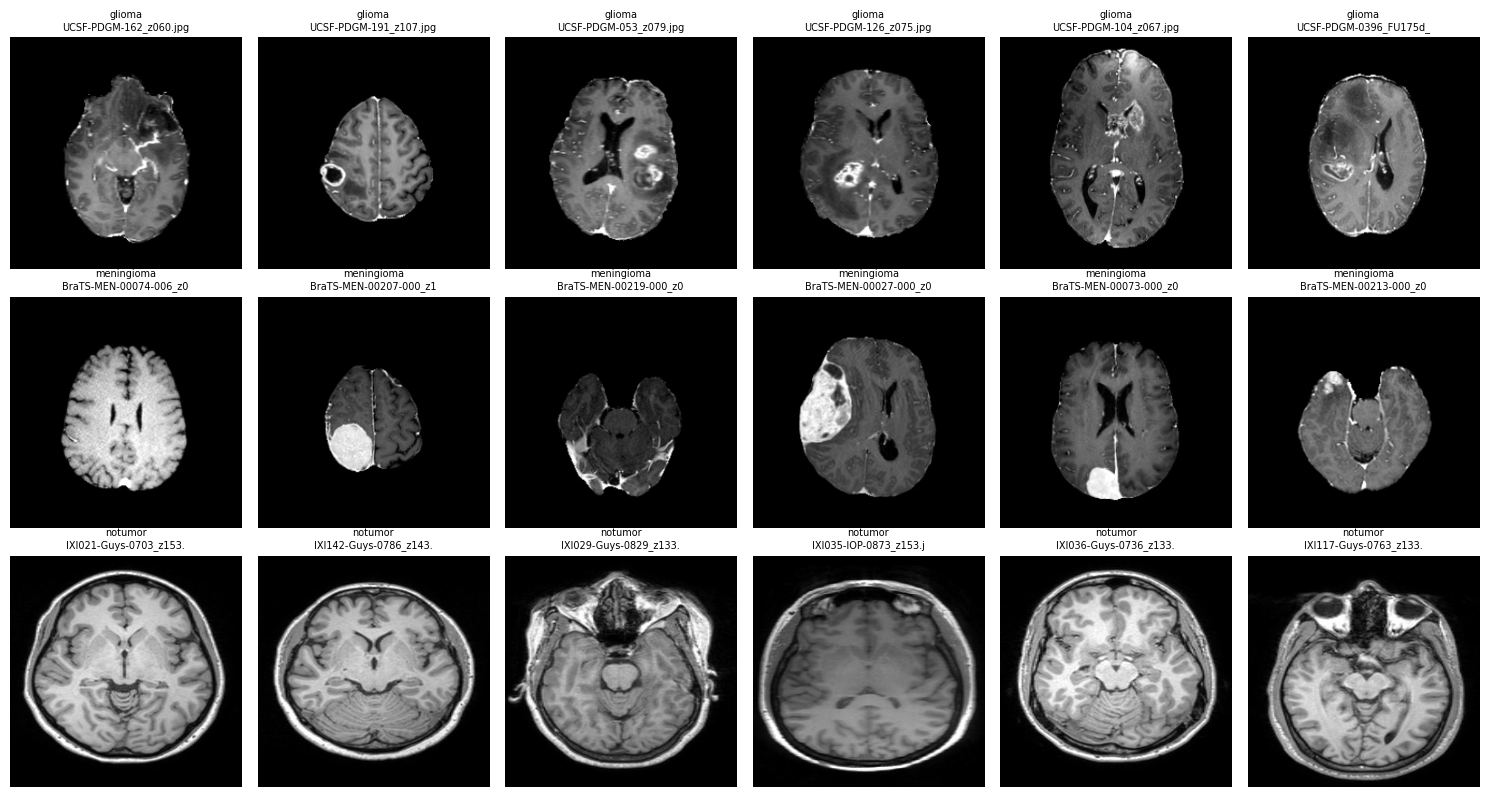

glioma 600 images
meningioma 599 images
notumor 600 images


In [2]:
# Kaggle notebook: build a 2D external test set from 3D MRI datasets
# ------------------------------------------------------------------
# Paste each "# %%" block into its own notebook cell (or paste it all into one cell).
# Output: /kaggle/working/external/{glioma,meningioma,notumor}/<patientID>_z###.jpg
# Patient ID is kept in every filename so you can split by patient later.

# %% ---------- Settings ----------
import os, glob, tarfile, shutil
import numpy as np
import nibabel as nib
import requests
from PIL import Image

OUT_DIR = "/kaggle/working/external"
IMG_SIZE = 256            # match your Kaggle training image size
SLICES_PER_PATIENT = 4    # 3-5 recommended for testing
MAX_PATIENTS = 150        # per class
RADIOLOGICAL = True       # patient's right on image left (typical clinical view)

# Paths to datasets attached via "Add Data" (look in the right-hand panel for the exact path)
GLIOMA_ROOT = "/kaggle/input/datasets/vietanh21/brats-2021-task-1-dataset"       # BraTS-style folders, one per patient

# Glioma = UCSF-PDGM. The full TCIA download is 142 GB (Aspera only), but every UCSF-PDGM
# case with a segmentation is also inside BraTS 2021, which is mirrored on Kaggle.
# UCSF-PDGM's clinical CSV (55 KB) maps each patient to its BraTS 2021 ID ("BraTS21 ID"),
# so we keep only those cases and name the output files by UCSF-PDGM ID.
UCSF_PDGM_ONLY = True
UCSF_CSV_URL = "https://www.cancerimagingarchive.net/wp-content/uploads/UCSF-PDGM-metadata_v5.csv"
MENINGIOMA_ROOT = "/kaggle/input/datasets/dukhailly/meningioma"

# IXI healthy controls are streamed straight from the source (Internet must be ON)
IXI_T1_URL = "http://biomedic.doc.ic.ac.uk/brain-development/downloads/IXI/IXI-T1.tar"
IXI_HOSPITALS = None      # e.g. ["HH"] to take only Hammersmith; None = any (Guys, HH, IOP)


# %% ---------- Helpers ----------
def resolve_nifti(path):
    """Some Kaggle mirrors store each scan as a FOLDER named like 'BraTS2021_00000_t1ce.nii'
    with the real .nii file inside. Return the real file in that case."""
    if os.path.isdir(path):
        inner = sorted(glob.glob(os.path.join(path, "**", "*.nii*"), recursive=True))
        inner = [f for f in inner if os.path.isfile(f)]
        if not inner:
            raise FileNotFoundError(f"No NIfTI file inside folder {path}")
        return inner[0]
    return path


def load_ras(path):
    """Load a NIfTI volume reoriented to RAS, so axis 2 is axial (inferior -> superior)."""
    img = nib.as_closest_canonical(nib.load(resolve_nifti(path)))
    return np.asarray(img.dataobj, dtype=np.float32)


def to_uint8(sl):
    """Per-slice intensity normalization (1st-99th percentile of non-zero voxels)."""
    nz = sl[sl > 0]
    if nz.size < 500:
        return None
    lo, hi = np.percentile(nz, [1, 99])
    sl = np.clip((sl - lo) / (hi - lo + 1e-6), 0, 1)
    return (sl * 255).astype(np.uint8)


def save_axial(vol, z, out_path):
    sl = to_uint8(vol[:, :, z])
    if sl is None:
        return False
    sl = np.rot90(sl)              # anterior at the top
    if RADIOLOGICAL:
        sl = np.fliplr(sl)
    Image.fromarray(sl).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR).save(out_path, quality=95)
    return True


def pick_tumor_slices(seg, n):
    """Pick n evenly spaced axial slices among those with >= 50% of the max tumor area.
    Uses tumor core (excludes edema, label 2 in BraTS) when present."""
    core = (seg > 0) & (seg != 2)
    mask = core if core.any() else (seg > 0)
    area = mask.sum(axis=(0, 1))
    if area.max() == 0:
        return []
    cand = np.where(area >= 0.5 * area.max())[0]
    if len(cand) <= n:
        return list(cand)
    return list(cand[np.linspace(0, len(cand) - 1, n).round().astype(int)])


def first_match(folder, patterns):
    for p in patterns:
        hits = glob.glob(os.path.join(folder, p))
        if hits:
            return hits[0]
    return None


# %% ---------- BraTS-style datasets (glioma, meningioma) ----------
def load_ucsf_mapping():
    """Return {BraTS2021_xxxxx: UCSF-PDGM-xxx} from the UCSF-PDGM clinical CSV."""
    import pandas as pd
    meta = pd.read_csv(UCSF_CSV_URL)
    meta = meta[meta["BraTS21 ID"].notna()]
    return dict(zip(meta["BraTS21 ID"].str.strip(), meta["ID"].str.strip()))


def process_brats(root, class_name, max_patients=MAX_PATIENTS, keep_ids=None):
    """keep_ids: optional {folder_name: output_name}; only those cases are used."""
    out = os.path.join(OUT_DIR, class_name)
    os.makedirs(out, exist_ok=True)
    cases = set()
    for p in glob.glob(f"{root}/**/*seg.nii*", recursive=True):
        d = os.path.dirname(p)
        if ".nii" in os.path.basename(d):   # match was the file inside a '*seg.nii' folder
            d = os.path.dirname(d)
        cases.add(d)
    cases = sorted(cases)
    if keep_ids is not None:
        cases = [c for c in cases if os.path.basename(c) in keep_ids]
    print(f"{class_name}: found {len(cases)} cases with segmentations")
    done = 0
    for case in cases:
        if done >= max_patients:
            break
        # BraTS 2021 names T1-contrast "_t1ce", BraTS 2023+ uses "-t1c"
        t1c = first_match(case, ["*t1ce.nii*", "*t1c.nii*"])
        seg = first_match(case, ["*seg.nii*"])
        if not (t1c and seg):
            continue
        try:
            vol, mask = load_ras(t1c), load_ras(seg)
        except Exception as e:
            print(f"  skipping {os.path.basename(case)}: {e}")
            continue
        pid = os.path.basename(case)
        if keep_ids is not None:
            pid = keep_ids[pid]
        zs = pick_tumor_slices(mask, SLICES_PER_PATIENT)
        saved = sum(save_axial(vol, z, f"{out}/{pid}_z{z:03d}.jpg") for z in zs)
        if saved:
            done += 1
    print(f"{class_name}: saved slices from {done} patients")


ucsf_map = load_ucsf_mapping() if UCSF_PDGM_ONLY else None
if ucsf_map is not None:
    print(f"UCSF-PDGM cases that are in BraTS 2021: {len(ucsf_map)}")
process_brats(GLIOMA_ROOT, "glioma", keep_ids=ucsf_map)
process_brats(MENINGIOMA_ROOT, "meningioma")


# %% ---------- IXI healthy controls (streamed, nothing large kept on disk) ----------
def process_ixi(max_patients=MAX_PATIENTS, hospitals=IXI_HOSPITALS):
    out = os.path.join(OUT_DIR, "notumor")
    tmp = "/tmp/ixi"
    os.makedirs(out, exist_ok=True)
    os.makedirs(tmp, exist_ok=True)
    done = 0
    with requests.get(IXI_T1_URL, stream=True, timeout=120) as r:
        r.raise_for_status()
        with tarfile.open(fileobj=r.raw, mode="r|") as tar:   # read the archive as a stream
            for m in tar:
                if done >= max_patients:
                    break                                     # stops the download early
                if not m.name.endswith(".nii.gz"):
                    continue
                name = os.path.basename(m.name)               # e.g. IXI002-Guys-0828-T1.nii.gz
                hospital = name.split("-")[1]
                if hospitals and hospital not in hospitals:
                    continue
                path = os.path.join(tmp, name)
                with open(path, "wb") as f:
                    shutil.copyfileobj(tar.extractfile(m), f)
                vol = load_ras(path)
                # No mask for healthy brains: take slices from the mid-to-upper brain
                # (ventricle level). Check the preview below and adjust the fractions if needed.
                nz = vol.shape[2]
                zs = (np.linspace(0.48, 0.60, SLICES_PER_PATIENT) * nz).astype(int)
                pid = name.replace("-T1.nii.gz", "")
                saved = sum(save_axial(vol, z, f"{out}/{pid}_z{z:03d}.jpg") for z in zs)
                os.remove(path)
                if saved:
                    done += 1
    print(f"notumor: saved slices from {done} patients")


process_ixi()


# %% ---------- Quick visual check ----------
import random
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for row, cls in enumerate(["glioma", "meningioma", "notumor"]):
    files = glob.glob(f"{OUT_DIR}/{cls}/*.jpg")
    for col, f in enumerate(random.sample(files, min(6, len(files)))):
        axes[row, col].imshow(Image.open(f), cmap="gray")
        axes[row, col].set_title(f"{cls}\n{os.path.basename(f)[:22]}", fontsize=7)
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout()
plt.show()


# %% ---------- Zip the result ----------
shutil.make_archive("/kaggle/working/external_slices", "zip", OUT_DIR)
for cls in sorted(os.listdir(OUT_DIR)):
    print(cls, len(os.listdir(os.path.join(OUT_DIR, cls))), "images")